# Detecting customer risk in bank complaints: an end-to-end NLP pipeline

**Research question.** How do baseline classifiers compare with transformer-based models in detecting customer risk
from complaints, and how can explainability techniques be applied to interpret their predictions?

**What this notebook does, in the order the work happens**

| Stage | What happens | Output |
|---|---|---|
| 1. Setup | Imports, paths, random seed, run switches | reproducible starting point |
| 2. Data | Load the CFPB complaints, decide the scope | filtered complaints |
| 3. Labels | Define "risk" (fraud / churn / other) from the structured fields | one label per complaint |
| 4. Text cleaning | Remove redaction tokens, drop near-empty texts | clean text |
| 5. Splits | Subsample and split **by time** into train / validation / test | three parquet files |
| 6. Baselines | TF-IDF with Logistic Regression and SVM, Word2Vec | scored baselines |
| 7. Error analysis | Why do the baselines get fraud wrong? | label-noise evidence |
| 8. Transformer | Fine-tune DistilBERT | scored transformer |
| 9. Comparison | Is the transformer really better? Paired tests | final results table |
| 10. Explainability | SHAP and a faithfulness test | *planned* |
| 11. Limitations and conclusions | What the results do and do not show | discussion |

**How to use it.** Run the cells from top to bottom. Each function is defined in the cell where it is first needed,
with the reasoning next to it. Slow steps are controlled by three switches in Stage 1, and results are saved to
`results/`, so a finished step is loaded from disk instead of repeated. Before handing the notebook in, use
*Kernel → Restart & Run All*.

> Cells marked **✍️ Your reasoning** are left for you to answer in your own words. They are where the report is marked.

## 1. Setup

Everything that must stay fixed for the results to be reproducible lives here: file locations, the random seed,
and the switches that decide whether slow steps re-run.

In [1]:
import os, re, time, random, platform
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Work from the folder that contains data/ and results/ (this notebook may live in a subfolder)
_start = os.getcwd()
for _ in range(3):
    if os.path.isdir("data"):
        break
    os.chdir("..")
else:
    os.chdir(_start)

# ---- locations ----
RAW_PATH = "data/raw/complaints.parquet"     # archived CFPB snapshot (see Stage 2)
PROCESSED_DIR = "data/processed"
RESULTS_DIR = "results"
FIG_DIR = f"{RESULTS_DIR}/figures"
for d in (PROCESSED_DIR, FIG_DIR, f"{RESULTS_DIR}/predictions", f"{RESULTS_DIR}/models"):
    os.makedirs(d, exist_ok=True)

# ---- reproducibility ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---- run switches (slow steps are skipped when saved results exist) ----
RERUN_BASELINES = False        # True: retrain the TF-IDF baselines even if results are saved
RUN_W2V = False                # True: also train the Word2Vec baseline (needs gensim)
TRANSFORMER_MODE = "off"       # "off" = load saved results | "benchmark" = time a few steps | "smoke" = tiny test run | "train" = full run

print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)

python 3.12.16 | pandas 3.1.0 | numpy 2.5.4


## 2. Data: source, scope and loading

**Source.** The CFPB Consumer Complaint Database. The CFPB removed complaint narratives from its live database in
September 2026, so this project uses an **archived snapshot of the same data** (a public-domain community mirror on
Hugging Face, `vivekkopthsd/cfpb-consumer-complaints`, covering complaints up to 11 August 2026). Verify the details on
the dataset page before you cite it.

**Scope.** The project is about *bank customers*, so we keep banking-type products and drop credit-reporting and
debt-collection complaints, which concern credit bureaus and collectors and dominate recent CFPB data. We also keep only
complaints from 2020 onward (so Issue names are consistent) that have a narrative (the text we classify).

> **✍️ Your reasoning:** Why this dataset? Who writes a complaint, and what are the strengths and weaknesses of
> complaints as evidence of customer risk (opt-in narratives, redaction, self-selection)? Defend each scope decision,
> and say what would change if credit reporting were included.

In [2]:
# Column names in the archived parquet mirror -> names used in this module
PARQUET_RENAME = {
    "date_received": "Date received",
    "product": "Product",
    "sub_product": "Sub-product",
    "issue": "Issue",
    "sub_issue": "Sub-issue",
    "narrative": "Consumer complaint narrative",
    "company_response": "Company response to consumer",
    "timely_response": "Timely response?",
    "complaint_id": "Complaint ID",
}

USECOLS = [
    "Date received", "Product", "Sub-product", "Issue", "Sub-issue",
    "Consumer complaint narrative", "Company response to consumer",
    "Timely response?", "Complaint ID",
]

# Scope: banking-type products only. Credit-reporting and debt-collection
# complaints are about credit bureaus / collectors, not bank customers, and
# they dominate recent CFPB data (about 90% of the sample), so they are excluded.
BANKING_PRODUCTS = {
    "Checking or savings account",
    "Bank account or service",
    "Credit card",
    "Credit card or prepaid card",
    "Prepaid card",
    "Money transfer, virtual currency, or money service",
    "Payday loan, title loan, personal loan, or advance loan",
    "Vehicle loan or lease",
    "Mortgage",
}

MIN_YEAR = 2020

`load_raw` reads the file and applies the scope. It filters while reading, so the full 17-million-row file never has
to fit in memory.

In [3]:
# ---------------------------------------------------------------------------
# LOADING
# ---------------------------------------------------------------------------
def load_raw(path: str, min_year: int = 2020) -> pd.DataFrame:
    if str(path).endswith(".parquet"):
        # Archived mirror (complaints.parquet). Filter while reading so the full
        # 17M-row file never has to fit in memory.
        import pyarrow.compute as pc
        import pyarrow.parquet as pq

        wanted = {**PARQUET_RENAME}
        file_cols = pq.ParquetFile(path).schema_arrow.names
        missing = [c for c in wanted if c not in file_cols]
        if missing:
            raise SystemExit(f"Parquet file is missing expected columns: {missing}\n"
                             f"Columns found: {file_cols}")
        keep = (pc.field("product").isin(sorted(BANKING_PRODUCTS))
                & pc.field("narrative").is_valid())
        df = (pq.read_table(path, columns=list(wanted), filters=keep)
                .to_pandas().rename(columns=wanted))
    else:
        header = pd.read_csv(path, nrows=0).columns
        missing = [c for c in USECOLS if c not in header]
        if "Consumer complaint narrative" in missing:
            raise SystemExit(
                "This CSV has no 'Consumer complaint narrative' column, so there is "
                "no text to classify. The CFPB removed narratives from its live "
                "database in September 2026; use an archived copy (parquet)."
            )
        if missing:
            raise SystemExit(f"CSV is missing expected columns: {missing}")
        df = pd.read_csv(path, usecols=USECOLS, low_memory=False)
        df = df.dropna(subset=["Consumer complaint narrative"])

    df = df[df["Consumer complaint narrative"].astype(str).str.strip() != ""]
    df["date"] = pd.to_datetime(df["Date received"])
    df = df[(df["date"].dt.year >= min_year) & df["Product"].isin(BANKING_PRODUCTS)].copy()
    return df

In [6]:
df.head(10)

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company response to consumer,Timely response?,Complaint ID,date
0,2024-02-12,Checking or savings account,Checking account,Managing an account,Deposits and withdrawals,From XXXX XXXX through XXXX XXXX my checking a...,Closed with explanation,Yes,8331660,2024-02-12
1,2025-11-24,"Money transfer, virtual currency, or money ser...",Virtual currency,Other transaction problem,NaN,"What happened? In XX/XX/year>, XXXX XXXX faile...",Closed with monetary relief,Yes,18854128,2025-11-24
2,2025-12-03,Mortgage,Conventional home mortgage,Closing on a mortgage,Closing disclosure or other related disclosures,"On XXXX, received a Loan Estimate from XXXX XX...",Closed with monetary relief,Yes,19007586,2025-12-03
3,2025-12-03,Mortgage,FHA mortgage,Trouble during payment process,Loan sold or transferred to another company,Subject : Request for Investigation Into Mortg...,Closed with explanation,Yes,17962227,2025-12-03
4,2026-01-24,Credit card,General-purpose credit card or charge card,Closing your account,Can't close your account,On XX/XX/year> I was notified by my bank that ...,Closed with non-monetary relief,Yes,18982774,2026-01-24
5,2026-01-29,Credit card,General-purpose credit card or charge card,Problem with a purchase shown on your statement,Card was charged for something you did not pur...,I SEEN A RETURN CHECK FEE THAT I NEVER INCRUDE...,Closed with explanation,Yes,19105114,2026-01-29
6,2026-02-05,Checking or savings account,Other banking product or service,Managing an account,Fee problem,Today on XXXX XXXX I was using the rain app to...,Closed with explanation,Yes,19277196,2026-02-05
7,2026-02-10,Credit card,Store credit card,Getting a credit card,Card opened without my consent or knowledge,I have tried to contact this company since XX/...,Closed with non-monetary relief,Yes,19371769,2026-02-10
8,2026-02-20,Credit card,General-purpose credit card or charge card,Problem when making payments,Problem during payment process,XXXX acct was paid in full {$2400.00} XXXX was...,Closed with explanation,Yes,19642783,2026-02-20
9,2026-02-20,Credit card,General-purpose credit card or charge card,Getting a credit card,Card opened without my consent or knowledge,I received an email from my XXXX XXXX and XXXX...,Closed with explanation,Yes,19642587,2026-02-20


In [4]:
df = load_raw(RAW_PATH, min_year=MIN_YEAR)
print(f"{len(df):,} complaints | {df['date'].min().date()} to {df['date'].max().date()}")
df["Product"].value_counts()

621,611 complaints | 2020-01-01 to 2026-07-21


Product
Checking or savings account                                167314
Money transfer, virtual currency, or money service         112553
Credit card                                                107695
Mortgage                                                    84652
Credit card or prepaid card                                 76504
Vehicle loan or lease                                       44661
Payday loan, title loan, personal loan, or advance loan     18126
Prepaid card                                                10106
Name: count, dtype: int64

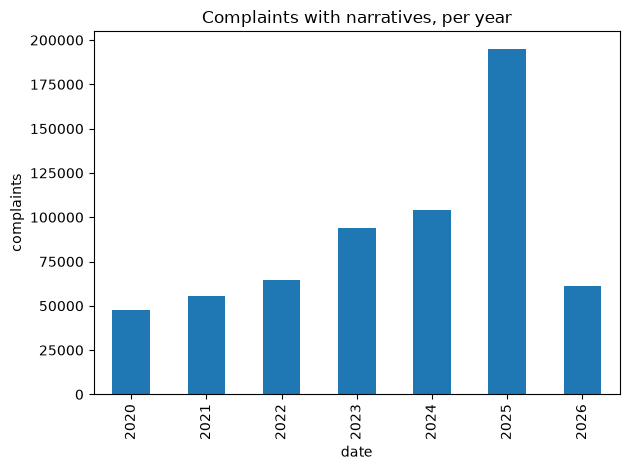

In [5]:
df.groupby(df["date"].dt.year).size().plot.bar(title="Complaints with narratives, per year")
plt.ylabel("complaints"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/complaints_per_year.png", dpi=150); plt.show()

## 3. Defining customer risk (the labels)

The CFPB data has no "risk" column, so we define one. Three mutually exclusive classes, with priority
**fraud > churn > other**:

- **fraud**: unauthorized activity, scams, accounts or cards opened without the person's consent
- **churn**: the customer is closing, or trying to close, an account
- **other**: everything else

**Key design rule: labels come only from the structured `Issue` and `Sub-issue` fields, never from the narrative.**
The models must then learn risk from the language itself. If the labels were built from keywords in the text, the models
would just rediscover those keywords (label leakage).

The rules below were refined by inspecting the real Issue counts. For example, issues like *"Credit monitoring or
identity theft protection services"* contain fraud-like words but are service complaints, so they are excluded.

In [7]:
FRAUD_PATTERN = re.compile(
    r"fraud|scam|unauthorized|identity theft|stolen|without my consent",
    re.I,
)

# Issues whose names contain fraud-like words but are NOT fraud events
# (service complaints or lost items), found by inspecting the real Issue counts.
NOT_FRAUD_ISSUES = {
    "credit monitoring or identity theft protection services",
    "problem with fraud alerts or security freezes",
    "lost or stolen money order",
    "lost or stolen check",
    "lost or stolen refund",
}

CHURN_ISSUES = {"closing an account", "closing your account"}

CHURN_SUBISSUE_PATTERN = re.compile(
    r"company closed|can.t close|closed account|trouble closing", re.I
)

LABELS = {"other": 0, "fraud": 1, "churn": 2}


def assign_label(issue: str, sub_issue: str) -> str:
    issue, sub_issue = str(issue), str(sub_issue)
    if (issue.strip().lower() not in NOT_FRAUD_ISSUES
            and FRAUD_PATTERN.search(f"{issue} {sub_issue}")):
        return "fraud"
    if issue.strip().lower() in CHURN_ISSUES or CHURN_SUBISSUE_PATTERN.search(sub_issue):
        return "churn"
    return "other"

Before applying the rules to 600,000 complaints, check them on cases we know the answer to.

In [8]:
cases = [
    ("Fraud or scam", "None", "fraud"),
    ("Unauthorized transactions or other transaction problem", "None", "fraud"),
    ("Getting a credit card", "Card opened without my consent or knowledge", "fraud"),
    ("Credit monitoring or identity theft protection services", "x", "other"),
    ("Problem with fraud alerts or security freezes", "None", "other"),
    ("Lost or stolen money order", "None", "other"),
    ("Closing an account", "None", "churn"),
    ("Closing your account", "Can't close your account", "churn"),
    ("Problem getting a card or closing an account", "Company closed your account", "churn"),
    ("Opening an account", "Unable to open an account", "other"),
    ("Closing on a mortgage", "Delays with the closing process", "other"),
    ("Managing an account", "Deposits and withdrawals", "other"),
]
for issue, sub, expected in cases:
    assert assign_label(issue, sub) == expected, (issue, sub, assign_label(issue, sub), expected)
print(f"All {len(cases)} rule checks pass")

All 12 rule checks pass


,n,share
label,,
other,531925,0.856
fraud,52211,0.084
churn,37475,0.060


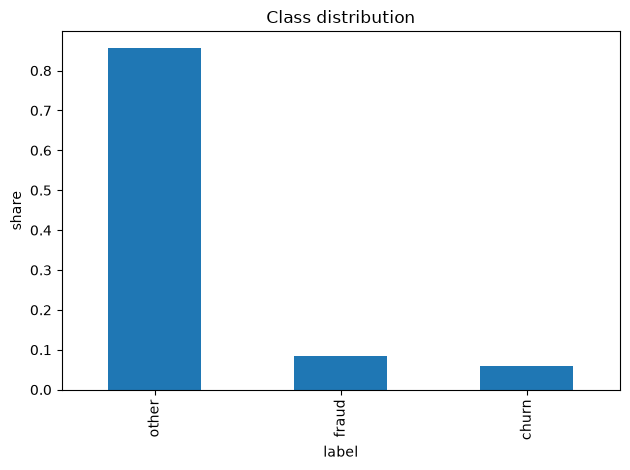

In [9]:
df["label"] = [assign_label(i, s) for i, s in zip(df["Issue"], df["Sub-issue"])]
df["label_id"] = df["label"].map(LABELS)

counts = df["label"].value_counts()
display(pd.DataFrame({"n": counts, "share": (counts / counts.sum()).round(3)}))
(counts / counts.sum()).reindex(["other", "fraud", "churn"]).plot.bar(title="Class distribution")
plt.ylabel("share"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/class_distribution.png", dpi=150); plt.show()

The table that belongs in the report: which Issues feed each risk class, and how large each is.

In [10]:
mapping = (df.groupby(["label", "Issue"]).size().rename("n").reset_index()
             .sort_values(["label", "n"], ascending=[True, False]))
for lab in ["fraud", "churn"]:
    print(f"--- Top Issues mapped to '{lab}' ---")
    display(mapping[mapping["label"] == lab].head(12).reset_index(drop=True))
mapping.to_csv(f"{RESULTS_DIR}/label_mapping_counts.csv", index=False)

--- Top Issues mapped to 'fraud' ---


,label,Issue,n
0,fraud,Fraud or scam,23860
1,fraud,Getting a credit card,11959
2,fraud,Unauthorized transactions or other transaction...,8977
3,fraud,Opening an account,5191
4,fraud,Getting a loan or lease,2224


--- Top Issues mapped to 'churn' ---


,label,Issue,n
0,churn,Closing an account,23342
1,churn,Closing your account,13163
2,churn,Problem getting a card or closing an account,970


> **✍️ Your reasoning:** Why are fraud and account closure the "risk" signals for a bank? What does building labels from
> the Issue field make easy, and what does it miss? (This is partly category prediction, and complaints arrive after the
> event, so this is risk *triage*, not forecasting.) Why were the exclusions above needed?

## 4. Cleaning the text

CFPB narratives are redacted: personal details are replaced with `XXXX`, and amounts appear as `{$12.00}`. These
placeholders carry no meaning for the model, so they are removed. Very short texts (under 10 words) are dropped, because
there is too little language to learn from.

In [11]:
# ---------------------------------------------------------------------------
# TEXT CLEANING
# ---------------------------------------------------------------------------
REDACTION = re.compile(r"\b(X{2,}|x{2,})\b|\{\$[\d.,]+\}")  # XXXX, {$12.00}


def clean_text(s: str) -> str:
    s = REDACTION.sub(" ", s)
    s = re.sub(r"\s+", " ", s)
    return s.strip()

In [12]:
raw_col = "Consumer complaint narrative"

# See what the cleaning does on a real example
has_redaction = df[df[raw_col].str.contains("XXXX", regex=False)]
if len(has_redaction):
    ex = has_redaction[raw_col].iloc[0]
    print("BEFORE:", ex[:300].replace("\n", " "))
    print("AFTER: ", clean_text(ex)[:300])

df["text"] = df[raw_col].map(clean_text)
df["n_words"] = df["text"].str.split().str.len()

MIN_WORDS = 10
before = len(df)
df = df[df["n_words"] >= MIN_WORDS].copy()
print(f"\nDropped {before - len(df):,} complaints with fewer than {MIN_WORDS} words; {len(df):,} remain")

BEFORE: From XXXX XXXX through XXXX XXXX my checking account went from XXXX to XXXX without my knowledge or consent. Notified the Chase Bank and filed a complaint to have my funds reimbursed and Chase Bank denied my request
AFTER:  From through my checking account went from to without my knowledge or consent. Notified the Chase Bank and filed a complaint to have my funds reimbursed and Chase Bank denied my request

Dropped 2,672 complaints with fewer than 10 words; 618,939 remain


**Text length matters for the transformer.** BERT-style models read at most 512 tokens, and attention cost grows with
length, so we will cap the input at 256 tokens. As a rough guide, 256 tokens is about 195 words.

count    618939.0
mean        214.8
std         234.7
min          10.0
25%          87.0
50%         150.0
75%         266.0
max        6263.0
Name: n_words, dtype: float64

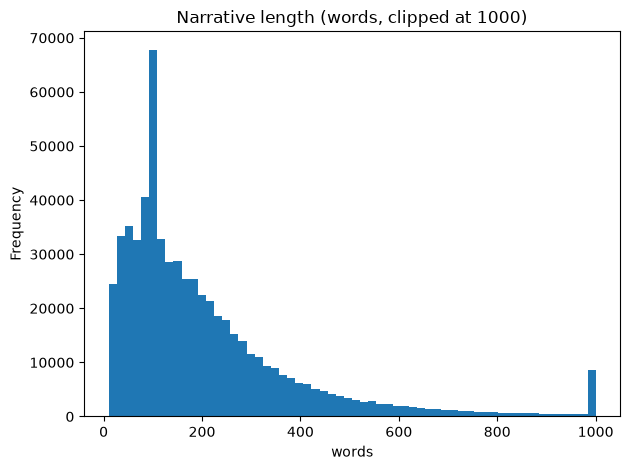

Share of complaints with <= 195 words (about 256 tokens): 62%


In [13]:
display(df["n_words"].describe().round(1))
df["n_words"].clip(upper=1000).plot.hist(bins=60, title="Narrative length (words, clipped at 1000)")
plt.xlabel("words"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/narrative_length.png", dpi=150); plt.show()
print(f"Share of complaints with <= 195 words (about 256 tokens): {(df['n_words'] <= 195).mean():.0%}")

In [14]:
# Read some real examples of each class (redacted text as published)
for lab in ["fraud", "churn", "other"]:
    for _, r in df[df["label"] == lab].sample(2, random_state=7).iterrows():
        print(f"[{lab.upper()}] Issue: {r['Issue']}")
        print(r["text"][:500], "...\n")

[FRAUD] Issue: Getting a credit card
I need help to file a dispute on a hard inquiry on my credit report from today. I received a spam text stating that there was a charge on my PayPal account and to call the number on the text. I always ignore potential scam messages and confirm myself. I went to log in directly on the PayPal app to check if theres been any transactions. As soon as I put my log in information, a blank screen comes up, then it loads a screen asking for my information. This information was my name, DOB, income, etc. ...

[FRAUD] Issue: Fraud or scam
I have a investor wallet with Blockfi, which is supposed to be in cold storage. The wallets are in my name and not to be used to satisfy secured creditors in case if bankruptcy comes. Also, I can not widraw my funds at this point. ...

[CHURN] Issue: Closing your account
One week after opening my account on / /year>, I received a letter dated / /year> stating that I needed to submit a form or my account would be closed. I ph

> **✍️ Your reasoning:** Which cleaning steps are justified by what you saw, and why? Why not also remove stopwords or
> stem for the transformer? (Stopword removal appears later, for the TF-IDF baselines only; think about why.)

## 5. Train / validation / test splits

Two decisions, both made to keep the evaluation honest:

1. **Subsample, keeping class ratios.** About 600,000 complaints is more than needed and too slow to fine-tune on, so we
   keep 60,000 with the same fraud/churn/other proportions (a *stratified* sample).
2. **Split by time, not at random.** The oldest 70% trains the model, the next 15% tunes it (validation), and the newest
   15% is the test set. A deployed model predicts on *future* complaints, so a random split would flatter it by letting it
   see the future.

> **✍️ Your reasoning:** Why a time-based split? What would a random split hide? Why is the test set touched only once,
> after all choices are made?

In [15]:
# ---------------------------------------------------------------------------
# BUILD SPLITS
# ---------------------------------------------------------------------------
def subsample_by_class(df: pd.DataFrame, n_total: int, seed: int) -> pd.DataFrame:
    """Stratified subsample: keep ~n_total rows with the same class proportions."""
    if len(df) <= n_total:
        return df
    return df.groupby("label").sample(frac=n_total / len(df), random_state=seed)


def time_split(df: pd.DataFrame, train_frac: float = 0.70, val_end: float = 0.85) -> dict:
    """Split by time: oldest 70% -> train, next 15% -> validation, newest 15% -> test."""
    df = df.sort_values("date").reset_index(drop=True)
    n = len(df)
    a, b = int(train_frac * n), int(val_end * n)
    return {"train": df.iloc[:a], "val": df.iloc[a:b], "test": df.iloc[b:]}

In [16]:
SUBSAMPLE_N = 60_000
sample = subsample_by_class(df, SUBSAMPLE_N, SEED)
parts = time_split(sample)

KEEP = ["Complaint ID", "date", "Product", "Issue", "text", "label", "label_id"]
for name, part in parts.items():
    part[KEEP].to_parquet(f"{PROCESSED_DIR}/{name}.parquet", index=False)

# From here on, always work from the saved files, exactly as a later session would
splits = {s: pd.read_parquet(f"{PROCESSED_DIR}/{s}.parquet") for s in ("train", "val", "test")}
summary = pd.DataFrame({
    s: {"rows": len(d), "from": d["date"].min().date(), "to": d["date"].max().date(),
        **d["label"].value_counts(normalize=True).round(3).to_dict()}
    for s, d in splits.items()}).T
display(summary)

,rows,from,to,other,fraud,churn
train,42000,2020-01-01,2025-02-13,0.864,0.078,0.057
val,9000,2025-02-13,2025-10-09,0.835,0.094,0.07
test,9000,2025-10-09,2026-07-21,0.837,0.099,0.064


The class mix **drifts over time** (see the shares above and the chart below). That is a real feature of the data, and
it means the test set is slightly harder than the validation set.

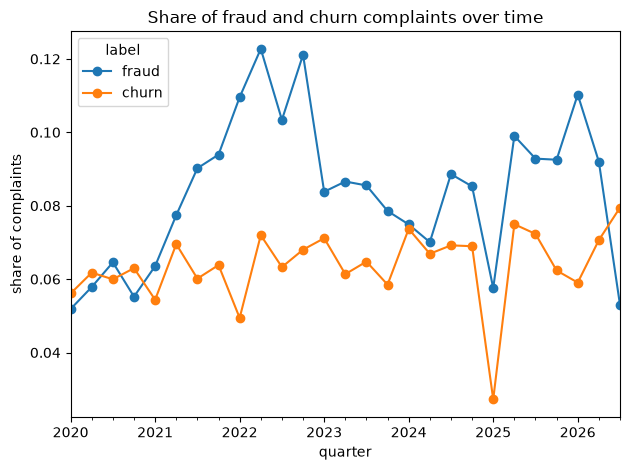

In [17]:
allp = pd.concat(splits.values())
allp["quarter"] = allp["date"].dt.to_period("Q").dt.to_timestamp()
share = allp.groupby("quarter")["label"].value_counts(normalize=True).unstack().fillna(0)
share[["fraud", "churn"]].plot(marker="o", title="Share of fraud and churn complaints over time")
plt.ylabel("share of complaints"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/class_drift.png", dpi=150); plt.show()

## 6. Baseline models

### 6.1 How we score models

Fraud and churn are minorities, so **accuracy is misleading**: a model that always answers "other" is right most of the
time and catches nothing. We therefore report **macro-F1** (the average of the per-class F1 scores, so each class counts
equally), plus per-class precision/recall, a macro PR-AUC, and a **bootstrap 95% confidence interval** for macro-F1 that
shows how much a score could move with a different sample of test complaints. The same functions score every model,
including the transformer later.

In [18]:
from matplotlib.figure import Figure
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from sklearn.preprocessing import label_binarize

LABEL_NAMES = ["other", "fraud", "churn"]   # index = label_id from data.py

LABEL_IDS = [0, 1, 2]


def compute_metrics(y_true, y_pred, scores=None) -> dict:
    """Accuracy, macro P/R/F1, per-class P/R/F1 and (if scores given) macro PR-AUC.

    scores: array of shape (n_samples, 3), class probabilities or decision values.
    """
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred),
           "macro_precision": p, "macro_recall": r, "macro_f1": f}
    pc, rc, fc, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABEL_IDS, zero_division=0)
    for i, name in enumerate(LABEL_NAMES):
        out[f"precision_{name}"] = pc[i]
        out[f"recall_{name}"] = rc[i]
        out[f"f1_{name}"] = fc[i]
    if scores is not None:
        Y = label_binarize(y_true, classes=LABEL_IDS)
        out["pr_auc_macro"] = average_precision_score(Y, scores, average="macro")
    return out


def bootstrap_macro_f1_ci(y_true, y_pred, n_boot=1000, seed=42, alpha=0.05):
    """95% bootstrap confidence interval for macro-F1 on the test set."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        stats.append(f1_score(y_true[idx], y_pred[idx], average="macro", zero_division=0))
    return (float(np.percentile(stats, 100 * alpha / 2)),
            float(np.percentile(stats, 100 * (1 - alpha / 2))))


def plot_confusion(y_true, y_pred, path, title=""):
    """Row-normalised confusion matrix (each row sums to 1 = recall per class)."""
    cm = confusion_matrix(y_true, y_pred, labels=LABEL_IDS, normalize="true")
    fig = Figure(figsize=(4.5, 4))
    ax = fig.subplots()
    im = ax.imshow(cm, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(3), LABEL_NAMES)
    ax.set_yticks(range(3), LABEL_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(path, dpi=150)

In [19]:
ytr, yva, yte = (splits[s]["label_id"].to_numpy() for s in ("train", "val", "test"))

# The floor: what a model that never flags anything would score
floor = compute_metrics(yte, np.zeros_like(yte))
print(f"Always predicting 'other': accuracy = {floor['accuracy']:.3f}, macro-F1 = {floor['macro_f1']:.3f}")

Always predicting 'other': accuracy = 0.837, macro-F1 = 0.304


> **✍️ Your reasoning:** Explain, using the numbers above, why accuracy would mislead here and why macro-F1 is the headline.
> What does the confidence interval tell a reader?

### 6.2 TF-IDF with Logistic Regression and a linear SVM

**TF-IDF** turns each complaint into a vector that gives high weight to words that are frequent in that complaint but rare
across all complaints (word pairs included). Rules that keep the evaluation honest:

- features are **fitted on the training split only**, so nothing leaks from validation or test;
- the regularisation strength `C` is **chosen on the validation split** (a time-ordered split must not be tuned with shuffled
  cross-validation), and the test set is scored once, after the choice;
- class weights are **"balanced"**, so the minority classes are not ignored.

In [20]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

GRIDS = {"tfidf_logreg": [1, 10, 100],
         "tfidf_svm": [0.1, 0.5, 1.0],
         "w2v_logreg": [0.1, 1, 10]}


def make_model(name, C):
    if name.endswith("logreg"):
        return LogisticRegression(C=C, max_iter=1000, class_weight="balanced",
                                  random_state=SEED)
    return LinearSVC(C=C, class_weight="balanced", random_state=SEED)


def get_scores(model, X):
    """(n, 3) scores: probabilities for LR, decision values for SVM."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)
    return model.decision_function(X)


def run_model(name, Xtr, ytr, Xva, yva, Xte, yte):
    """Pick C on validation macro-F1, then score once on test."""
    best = None
    for C in GRIDS[name]:
        t0 = time.time()
        m = make_model(name, C).fit(Xtr, ytr)
        val_f1 = compute_metrics(yva, m.predict(Xva))["macro_f1"]
        print(f"  [{name}] C={C:<6} val macro-F1={val_f1:.4f}  ({time.time()-t0:.0f}s)")
        if best is None or val_f1 > best[0]:
            best = (val_f1, C, m)
    val_f1, C, model = best
    pred = model.predict(Xte)
    scores = get_scores(model, Xte)
    metrics = compute_metrics(yte, pred, scores)
    lo, hi = bootstrap_macro_f1_ci(yte, pred)
    row = {"model": name, "best_C": C, "val_macro_f1": val_f1, **metrics,
           "macro_f1_ci_low": lo, "macro_f1_ci_high": hi}
    return row, model, pred

In [21]:
def save_results(rows, path):
    """Write result rows to a CSV, replacing rows of the same model and keeping the others."""
    new = pd.DataFrame(rows)
    if os.path.exists(path):
        old = pd.read_csv(path)
        new = pd.concat([old[~old["model"].isin(new["model"])], new], ignore_index=True)
    new.to_csv(path, index=False)
    return new

def save_run(name, pred):
    """Save a model's test predictions (for later significance tests) and its confusion matrix."""
    pd.DataFrame({"Complaint ID": splits["test"]["Complaint ID"].to_numpy(), "y_true": yte, "y_pred": pred}
                 ).to_parquet(f"{RESULTS_DIR}/predictions/{name}_test.parquet", index=False)
    plot_confusion(yte, pred, f"{FIG_DIR}/cm_{name}.png", name)

In [22]:
BASE_CSV = f"{RESULTS_DIR}/baseline_results.csv"

if RERUN_BASELINES or not os.path.exists(BASE_CSV):
    vec = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2),
                          min_df=5, max_df=0.9, max_features=200_000, sublinear_tf=True)
    Xtr = vec.fit_transform(splits["train"]["text"])            # fit on TRAIN only
    Xva, Xte = vec.transform(splits["val"]["text"]), vec.transform(splits["test"]["text"])
    print(f"TF-IDF: {Xtr.shape[1]:,} features")

    rows, fitted = [], {}
    for name in ("tfidf_logreg", "tfidf_svm"):
        row, model, pred = run_model(name, Xtr, ytr, Xva, yva, Xte, yte)
        rows.append(row); fitted[name] = model
        save_run(name, pred)

    # The 25 highest-weighted terms per class from Logistic Regression: the baseline's global explanation
    lr, terms = fitted["tfidf_logreg"], np.array(vec.get_feature_names_out())
    top = [{"class": cls, "term": terms[j], "coef": lr.coef_[k][j]}
           for k, cls in enumerate(LABEL_NAMES) for j in np.argsort(lr.coef_[k])[::-1][:25]]
    pd.DataFrame(top).to_csv(f"{RESULTS_DIR}/lr_top_terms.csv", index=False)
    save_results(rows, BASE_CSV)
else:
    print("Loading saved baseline results (set RERUN_BASELINES = True to retrain).")

base = pd.read_csv(BASE_CSV)
cols = ["model", "best_C", "val_macro_f1", "accuracy", "macro_f1", "macro_f1_ci_low", "macro_f1_ci_high",
        "pr_auc_macro", "f1_fraud", "f1_churn"]
display(base[cols].round(4))

Loading saved baseline results (set RERUN_BASELINES = True to retrain).


,model,best_C,val_macro_f1,accuracy,macro_f1,macro_f1_ci_low,macro_f1_ci_high,pr_auc_macro,f1_fraud,f1_churn
0,tfidf_logreg,10.0,0.6568,0.8430,0.6668,0.6507,0.6830,0.6822,0.5245,0.5683
1,tfidf_svm,0.1,0.6578,0.8521,0.6660,0.6504,0.6815,0.6889,0.5111,0.5723
2,w2v_logreg,1.0,0.5504,0.6980,0.5601,0.5467,0.5733,0.6126,0.4614,0.4212


### 6.3 Word2Vec (optional)

Instead of counting words, Word2Vec learns a vector per word from the training complaints, and a complaint is the average of
its word vectors. Averaging throws away word-level detail, so this is expected to be weaker than TF-IDF. It needs `gensim`
(set `RUN_W2V = True` in Stage 1).

In [23]:
def tokenize(text, drop_stop):
    toks = re.findall(r"[a-z']+", text.lower())
    return [t for t in toks if not (drop_stop and t in ENGLISH_STOP_WORDS)]


def doc_vectors(token_lists, wv):
    dim = wv.vector_size
    out = np.zeros((len(token_lists), dim), dtype=np.float32)
    for i, toks in enumerate(token_lists):
        vecs = [wv[t] for t in toks if t in wv]
        if vecs:
            out[i] = np.mean(vecs, axis=0)
    return out

if RUN_W2V:
    from gensim.models import Word2Vec
    tok = {s: [tokenize(t, True) for t in splits[s]["text"]] for s in splits}
    # workers=1 keeps training reproducible for a fixed seed
    w2v = Word2Vec(tok["train"], vector_size=200, window=5, min_count=5, workers=1, epochs=5, seed=SEED)
    print("Nearest words to 'fraud':", [w for w, _ in w2v.wv.most_similar("fraud", topn=8)])
    Wtr, Wva, Wte = (doc_vectors(tok[s], w2v.wv) for s in ("train", "val", "test"))
    row, model, pred = run_model("w2v_logreg", Wtr, ytr, Wva, yva, Wte, yte)
    save_results([row], BASE_CSV); save_run("w2v_logreg", pred)
    base = pd.read_csv(BASE_CSV); display(base[cols].round(4))
else:
    print("Skipped (RUN_W2V = False). Any saved Word2Vec result is already in the table above.")

Skipped (RUN_W2V = False). Any saved Word2Vec result is already in the table above.


### 6.4 What did the baselines learn?

Each row of a confusion matrix shows where the true cases of a class end up, so the diagonal is the recall.

tfidf_logreg


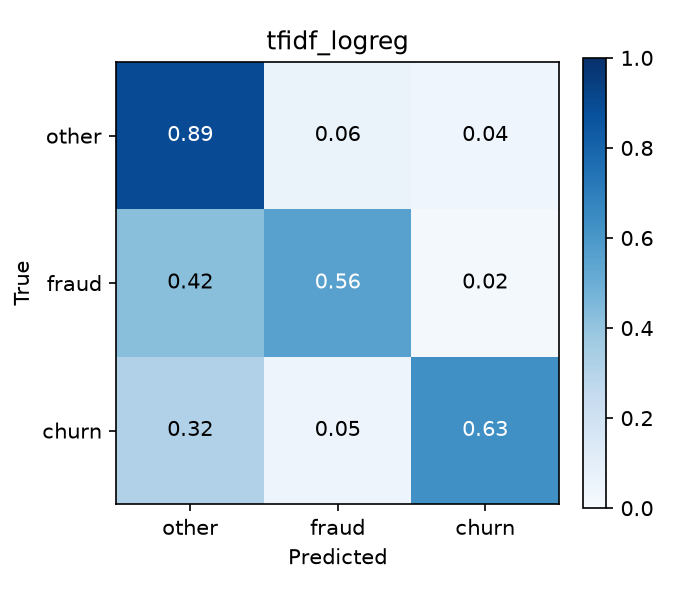

tfidf_svm


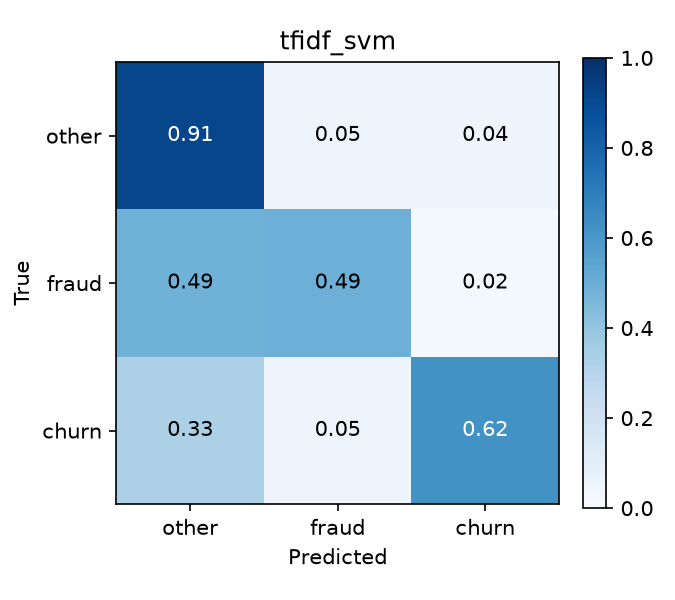

w2v_logreg


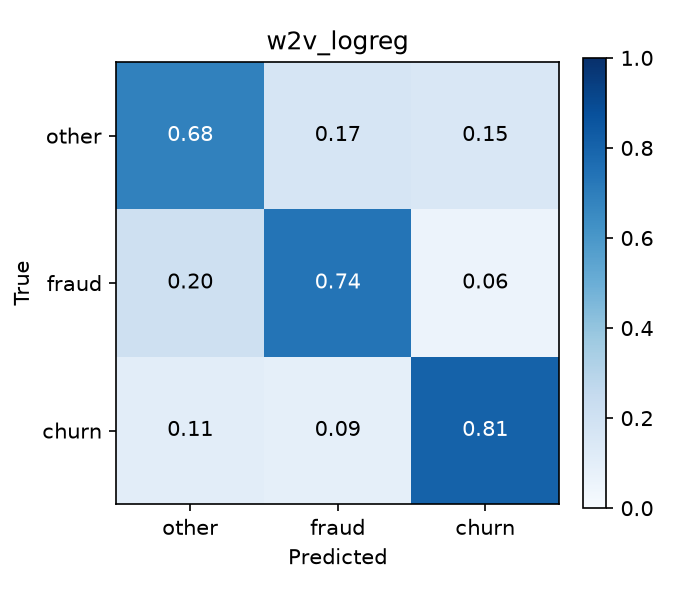

In [24]:
for m in base["model"]:
    print(m)
    display(Image(f"{FIG_DIR}/cm_{m}.png", width=380))

The highest-weighted words per class from Logistic Regression: the baseline's own explanation, and what SHAP will later be
compared against.

In [25]:
terms = pd.read_csv(f"{RESULTS_DIR}/lr_top_terms.csv")
view = {c: terms[terms["class"] == c].head(15).reset_index(drop=True)[["term", "coef"]] for c in ["fraud", "churn"]}
display(pd.concat(view, axis=1).round(2))
display(base[["model", "precision_fraud", "recall_fraud", "precision_churn", "recall_churn"]].round(3))

fraud                  churn       
           term  coef             term   coef
0        opened  7.11           closed  16.54
1        paypal  7.00            close  11.60
2          scam  6.24          closure   9.80
3         venmo  6.17          closing   7.49
4          open  5.59               cd   6.66
5         zelle  5.53  closing account   6.35
6       scammed  5.47    close account   5.75
7   card opened  5.01           branch   5.65
8         fraud  4.93   charged credit   5.64
9       cashapp  4.85          account   4.95
10          fbi  4.71   account closed   4.51
11     cash app  4.63            check   4.43
12     did open  4.60   closed account   4.37
13     coinbase  4.59      bank closed   4.25
14  application  4.49           reason   4.17

,model,precision_fraud,recall_fraud,precision_churn,recall_churn
0,tfidf_logreg,0.495,0.558,0.516,0.632
1,tfidf_svm,0.530,0.493,0.530,0.622
2,w2v_logreg,0.336,0.738,0.285,0.808


> **✍️ Your reasoning:** Compare the models. Do the confidence intervals of the two TF-IDF models overlap, and what does that
> mean? Why is Word2Vec weaker? Do the top terms make sense for fraud and churn, and are there any artefacts? In the confusion
> matrix, is the hard part fraud vs churn, or risk vs no-risk?

## 7. Error analysis: are the false fraud alarms really mistakes?

A fraud F1 around 0.5 could mean a weak model **or** noisy labels. The Issue field is a dropdown choice, and broad
categories such as "Managing an account" can hold complaints that describe fraud. Method: see which Issues the false
alarms come from, compare fraud-like language between false alarms and correctly-"other" complaints, and read examples.

In [26]:
import textwrap
test = splits["test"]
preds = pd.read_parquet(f"{RESULTS_DIR}/predictions/tfidf_logreg_test.parquet")
d = test.merge(preds[["Complaint ID", "y_pred"]], on="Complaint ID")
fp = d[(d["label_id"] == 0) & (d["y_pred"] == 1)]
ok = d[(d["label_id"] == 0) & (d["y_pred"] == 0)]
tp = ((d["label_id"] == 1) & (d["y_pred"] == 1)).sum()
print(f"Fraud precision: {tp / (d['y_pred'] == 1).sum():.3f} | false fraud alarms: {len(fp)}")
display(fp["Issue"].value_counts().head(10))

pat = r"fraud|unauthori[sz]ed|scam|stolen|hack|did not (make|authori[sz]e)|didn.t (make|authori[sz]e)"
print(f"Share using fraud-like words | false alarms:       {fp['text'].str.contains(pat, case=False, regex=True).mean():.2f}")
print(f"Share using fraud-like words | correctly 'other': {ok['text'].str.contains(pat, case=False, regex=True).mean():.2f}")

Fraud precision: 0.495 | false fraud alarms: 479


Issue
Managing an account                                                133
Other transaction problem                                           64
Problem with a purchase shown on your statement                     52
Problem with a lender or other company charging your account        47
Incorrect information on your report                                19
Trouble accessing funds in your mobile or digital wallet            18
Opening an account                                                  15
Getting a credit card                                               12
Other features, terms, or problems                                  10
Problem with a company's investigation into an existing problem      9
Name: count, dtype: int64

Share using fraud-like words | false alarms:       0.67
Share using fraud-like words | correctly 'other': 0.28


/var/folders/p9/5rh9q_mn507043rk_w3993jc0000gn/T/ipykernel_43296/2360715315.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print(f"Share using fraud-like words | false alarms:       {fp['text'].str.contains(pat, case=False, regex=True).mean():.2f}")
/var/folders/p9/5rh9q_mn507043rk_w3993jc0000gn/T/ipykernel_43296/2360715315.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print(f"Share using fraud-like words | correctly 'other': {ok['text'].str.contains(pat, case=False, regex=True).mean():.2f}")


In [27]:
for _, r in fp.sample(min(8, len(fp)), random_state=1).iterrows():
    print("ISSUE:", r["Issue"])
    print(textwrap.fill(r["text"][:450], 100), "...\n")

ISSUE: Managing an account
On / /year>, fraudulent wire transfers were made from my checking account at Chase Bank. They
transferred the money from my savings account to my checking account. I did not authorize them was
not receiving any alerts from the bank, because my phone had been hacked. My sister came to my
house, because she could not reach me. We immediately went to and reported the fraud and got a new
phone number. Once I got home, I contacted Chase to let them kn ...

ISSUE: Problem with a lender or other company charging your account
I got scammed on / /2026 from I was selling a bike he wanted to send money threw and I received an
email from it would not go through bc of the limit amount it didnt go through do I order to get I
had to send extra money and then it would get deposited back I thought it was ok bc I called and
said yes. The called back and said it already paid and the cound not get it back they did with
chime, and all with my email only. I feel I should get it ba

> **✍️ Your reasoning:** From the Issues, the keyword shares and the examples you read: how much of the "error" looks like label
> noise rather than model failure? What does that imply for the best score any model could reach? (You read only a few examples;
> say how many, and what that can and cannot show.)

## 8. Transformer: fine-tuning DistilBERT

TF-IDF treats a complaint as a bag of words. A transformer reads words **in context**, so "I did not authorize this charge"
and "I authorized this charge" look different to it. **DistilBERT** is a smaller, faster distilled version of BERT, chosen
because the compute available here is limited.

How it is set up (matching the baselines so the comparison is fair):

- the same train / validation / test files and the same scoring functions;
- **class-weighted** loss, like the baselines' "balanced" weights;
- input cut at **256 tokens** (Stage 4);
- the **best epoch is chosen on validation** macro-F1, and the test set is scored once at the end;
- several random seeds can be run, because fine-tuning varies a little from run to run.

**Compute note.** Training is slow on a laptop. Use `TRANSFORMER_MODE = "benchmark"` first: it times a few training steps and
projects the run time. Then `"smoke"` runs a tiny end-to-end test, and `"train"` does the real run. The same work can be run from the
terminal with `python -m src.transformer` (useful, because it survives closing the browser). On a Mac, PyTorch must match your macOS
version for the Apple GPU to work; if it crashes, use `device="cpu"` in the configuration below.

> **✍️ Your reasoning:** Why might a transformer beat TF-IDF here, and why might the gain be limited (think about the labels)?
> Why DistilBERT, and what does the 256-token limit cost?

In [28]:
CFG = SimpleNamespace(
    model="distilbert-base-uncased",
    max_len=256,          # tokens kept per complaint
    epochs=2,
    batch_size=16,
    lr=2e-5,
    seeds=[42],           # e.g. [42, 43, 44] for mean +/- std
    max_train=15000,      # training rows used (0 = all 42,000). Smaller = faster
    max_val=0, max_test=0, subsample_seed=42,
    device="auto",        # "auto" | "cpu" | "mps" | "cuda"
    no_save_model=False,
)
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")     # Apple GPU: fall back to CPU for rare ops
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
NUM_LABELS = 3

### 8.1 Preparing the data: a balanced sample, tokens, batches

The network works on batches of token ids. `encode` converts text to ids (cut at `max_len`), and `make_batch` pads the
complaints in a batch to the same length. Class weights make a mistake on a rare class cost more.

In [29]:
# ----------------------------------------------------------------------------
# helpers that do not need torch (these are unit-testable on their own)
# ----------------------------------------------------------------------------
def stratified_subsample(df, n, seed):
    """Keep ~n rows with the same class proportions. n<=0 means keep all."""
    if n <= 0 or n >= len(df):
        return df.reset_index(drop=True)
    return (df.groupby("label_id").sample(frac=n / len(df), random_state=seed)
              .reset_index(drop=True))


def balanced_class_weights(y, k=NUM_LABELS):
    """n / (k * n_c): the same 'balanced' rule scikit-learn used for the baselines."""
    counts = np.bincount(y, minlength=k).astype(float)
    return len(y) / (k * np.maximum(counts, 1.0))


def softmax(logits):
    z = logits - logits.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def encode(tokenizer, texts, max_len):
    """Token ids only, truncated to max_len. Padding happens per batch."""
    return tokenizer(list(texts), truncation=True, max_length=max_len)["input_ids"]


def make_batch(ids_list, labels, idx, pad_id, device):
    import torch
    seqs = [ids_list[i] for i in idx]
    L = max(len(s) for s in seqs)
    input_ids = torch.full((len(seqs), L), pad_id, dtype=torch.long)
    attn = torch.zeros((len(seqs), L), dtype=torch.long)
    for r, s in enumerate(seqs):
        input_ids[r, :len(s)] = torch.tensor(s, dtype=torch.long)
        attn[r, :len(s)] = 1
    y = torch.tensor(np.asarray(labels)[idx], dtype=torch.long)
    return input_ids.to(device), attn.to(device), y.to(device)

### 8.2 The model and the training loop

`train_one_seed` fine-tunes the model for a few epochs. After each epoch it scores the **validation** set and keeps the best
weights; the **test** set is scored once, at the end, and the predictions are saved for the comparison in Stage 9.

In [30]:
# ----------------------------------------------------------------------------
# torch helpers
# ----------------------------------------------------------------------------
def pick_device(choice="auto"):
    """choice: 'auto' (cuda > mps > cpu), or force 'cpu' / 'mps' / 'cuda'."""
    import torch
    if choice != "auto":
        return torch.device(choice)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def sync(device):
    import torch
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def set_seed(seed):
    import torch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def predict_logits(model, ids_list, pad_id, device, batch_size=64):
    import torch
    model.eval()
    order = np.argsort([len(s) for s in ids_list])        # length-sorted = less padding
    out = np.zeros((len(ids_list), NUM_LABELS), dtype=np.float32)
    dummy = np.zeros(len(ids_list), dtype=int)
    with torch.no_grad():
        for start in range(0, len(order), batch_size):
            idx = order[start:start + batch_size]
            x, m, _ = make_batch(ids_list, dummy, idx, pad_id, device)
            out[idx] = model(input_ids=x, attention_mask=m).logits.float().cpu().numpy()
    return out


def load_model(name, device):
    from transformers import AutoModelForSequenceClassification
    id2label = {i: n for i, n in enumerate(LABEL_NAMES)}
    model = AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=NUM_LABELS, id2label=id2label,
        label2id={n: i for i, n in id2label.items()})
    return model.to(device)


# ----------------------------------------------------------------------------
# one full training run (one seed)
# ----------------------------------------------------------------------------
def train_one_seed(args, seed, name, ids, labels, test_df, pad_id, device, res):
    import torch
    from transformers import get_linear_schedule_with_warmup

    ids_tr, ids_va, ids_te = ids["train"], ids["val"], ids["test"]
    ytr, yva, yte = labels["train"], labels["val"], labels["test"]

    set_seed(seed)
    model = load_model(args.model, device)
    weights = torch.tensor(balanced_class_weights(ytr), dtype=torch.float32).to(device)
    loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=0.01)
    steps_per_epoch = int(np.ceil(len(ids_tr) / args.batch_size))
    total_steps = steps_per_epoch * args.epochs
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * total_steps), total_steps)
    rng = np.random.default_rng(seed)

    best_f1, best_epoch, best_state = -1.0, 0, None
    t_start = time.time()
    step = 0
    for epoch in range(1, args.epochs + 1):
        model.train()
        perm = rng.permutation(len(ids_tr))
        for start in range(0, len(perm), args.batch_size):
            idx = perm[start:start + args.batch_size]
            x, m, y = make_batch(ids_tr, ytr, idx, pad_id, device)
            loss = loss_fn(model(input_ids=x, attention_mask=m).logits, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            opt.zero_grad()
            step += 1
            if step % 50 == 0 or step == total_steps:
                el = time.time() - t_start
                eta = el / step * (total_steps - step)
                print(f"  [{name}] epoch {epoch} step {step}/{total_steps} "
                      f"loss {loss.item():.4f} | {el/60:.1f} min elapsed, ~{eta/60:.1f} min left")
        val_pred = predict_logits(model, ids_va, pad_id, device).argmax(1)
        val_f1 = compute_metrics(yva, val_pred)["macro_f1"]
        print(f"  [{name}] epoch {epoch} validation macro-F1 = {val_f1:.4f}")
        if val_f1 > best_f1:
            best_f1, best_epoch = val_f1, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    logits = predict_logits(model, ids_te, pad_id, device)
    probs, pred = softmax(logits), logits.argmax(1)
    metrics = compute_metrics(yte, pred, probs)
    lo, hi = bootstrap_macro_f1_ci(yte, pred)

    (res / "predictions").mkdir(parents=True, exist_ok=True)
    (res / "figures").mkdir(parents=True, exist_ok=True)
    out = pd.DataFrame({"Complaint ID": test_df["Complaint ID"].to_numpy(),
                        "y_true": yte, "y_pred": pred})
    for k, n in enumerate(LABEL_NAMES):
        out[f"p_{n}"] = probs[:, k]
    out.to_parquet(res / "predictions" / f"{name}_test.parquet", index=False)
    plot_confusion(yte, pred, res / "figures" / f"cm_{name}.png", name)
    if not args.no_save_model:
        mdir = res / "models" / name
        model.save_pretrained(mdir)
    return {"model": name, "seed": seed, "best_epoch": best_epoch,
            "val_macro_f1": best_f1, **metrics,
            "macro_f1_ci_low": lo, "macro_f1_ci_high": hi,
            "train_minutes": (time.time() - t_start) / 60}

### 8.3 Time it first

`run_benchmark` runs a few training steps and projects how long a full run would take on **your** machine, so you can pick
`max_train` before committing.

In [31]:
# ----------------------------------------------------------------------------
# benchmark: time a few training steps and project the full run
# ----------------------------------------------------------------------------
def run_benchmark(args, ids_tr, ytr, n_eval, pad_id, device):
    import torch
    set_seed(0)
    model = load_model(args.model, device)
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr)
    loss_fn = torch.nn.CrossEntropyLoss()
    rng = np.random.default_rng(0)
    times = []
    for step in range(23):                                  # 3 warm-up + 20 timed
        idx = rng.choice(len(ids_tr), args.batch_size, replace=False)
        x, m, y = make_batch(ids_tr, ytr, idx, pad_id, device)
        sync(device)
        t0 = time.time()
        loss = loss_fn(model(input_ids=x, attention_mask=m).logits, y)
        loss.backward()
        opt.step()
        opt.zero_grad()
        sync(device)
        if step >= 3:
            times.append(time.time() - t0)
    spb = float(np.mean(times))
    steps = int(np.ceil(len(ids_tr) / args.batch_size))
    train_min = spb * steps / 60
    eval_min = spb / 3 * n_eval / args.batch_size / 60      # forward-only is ~1/3 the cost
    print(f"\ndevice: {device} | {spb:.2f} s/step at batch size {args.batch_size}, "
          f"max_len {args.max_len}")
    print(f"training examples: {len(ids_tr):,} -> about {train_min:.0f} min per epoch")
    print(f"evaluation (val each epoch + test once): about {eval_min:.1f} min per pass over "
          f"{n_eval:,} examples")
    total = args.epochs * train_min + (args.epochs + 1) * eval_min
    print(f"projected time for ONE seed with {args.epochs} epochs: ~{total:.0f} min "
          f"(rough estimate, +/-30%)")

### 8.4 Run it

Set `TRANSFORMER_MODE` in Stage 1: `"benchmark"`, `"smoke"` or `"train"`. With `"off"`, this cell does nothing and Stage 9
loads results saved by an earlier run.

In [35]:
TF_CSV = f"{RESULTS_DIR}/transformer_results.csv"

if TRANSFORMER_MODE == "smoke":
    print("TRANSFORMER_MODE = 'off': not training. Saved transformer results (if any) are loaded in Stage 9.")
else:
    from transformers import AutoTokenizer
    smoke = TRANSFORMER_MODE == "smoke"
    cfg = SimpleNamespace(**vars(CFG))
    res_dir = Path(RESULTS_DIR)
    if smoke:                                                    # tiny end-to-end check, kept apart from real results
        cfg.max_train, cfg.max_val, cfg.max_test, cfg.epochs, cfg.seeds = 600, 300, 300, 1, CFG.seeds[:1]
        res_dir = res_dir / "smoke"

    device = pick_device(cfg.device)
    print("device:", device)
    data = {"train": stratified_subsample(splits["train"], cfg.max_train, cfg.subsample_seed),
            "val": stratified_subsample(splits["val"], cfg.max_val, cfg.subsample_seed),
            "test": stratified_subsample(splits["test"], cfg.max_test, cfg.subsample_seed)}
    print({s: len(v) for s, v in data.items()})

    tokenizer = AutoTokenizer.from_pretrained(cfg.model)
    ids = {s: encode(tokenizer, data[s]["text"], cfg.max_len) for s in data}
    labels = {s: data[s]["label_id"].to_numpy() for s in data}
    pad_id = tokenizer.pad_token_id
    hit = np.mean([len(x) >= cfg.max_len for x in ids["train"]])
    print(f"{hit:.0%} of training texts hit the {cfg.max_len}-token limit")

    if TRANSFORMER_MODE == "benchmark":
        run_benchmark(cfg, ids["train"], labels["train"], len(ids["val"]) + len(ids["test"]), pad_id, device)
    else:
        for seed in cfg.seeds:
            name = f"{Path(cfg.model).name}_s{seed}" + ("_smoke" if smoke else "")
            print(f"\n=== {name} ===")
            row = train_one_seed(cfg, seed, name, ids, labels, data["test"], pad_id, device, res_dir)
            save_results([row], str(res_dir / "transformer_results.csv"))   # saved after every seed
        print("Done. Results saved in", res_dir)

device: mps
{'train': 14999, 'val': 9000, 'test': 9000}
32% of training texts hit the 256-token limit

=== distilbert-base-uncased_s42 ===


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 6348.85it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [distilbert-base-uncased_s42] epoch 1 step 50/1876 loss 1.1283 | 0.7 min elapsed, ~25.8 min left
  [distilbert-base-uncased_s42] epoch 1 step 100/1876 loss 0.9661 | 1.4 min elapsed, ~25.0 min left
  [distilbert-base-uncased_s42] epoch 1 step 150/1876 loss 1.0358 | 2.1 min elapsed, ~24.2 min left
  [distilbert-base-uncased_s42] epoch 1 step 200/1876 loss 1.0376 | 2.8 min elapsed, ~23.5 min left
  [distilbert-base-uncased_s42] epoch 1 step 250/1876 loss 0.6304 | 3.5 min elapsed, ~22.8 min left
  [distilbert-base-uncased_s42] epoch 1 step 300/1876 loss 0.2460 | 4.2 min elapsed, ~22.0 min left
  [distilbert-base-uncased_s42] epoch 1 step 350/1876 loss 0.9646 | 4.9 min elapsed, ~21.3 min left
  [distilbert-base-uncased_s42] epoch 1 step 400/1876 loss 1.2716 | 5.6 min elapsed, ~20.6 min left
  [distilbert-base-uncased_s42] epoch 1 step 450/1876 loss 0.2476 | 6.4 min elapsed, ~20.3 min left
  [distilbert-base-uncased_s42] epoch 1 step 500/1876 loss 0.4850 | 7.3 min elapsed, ~20.1 min left
 

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.24it/s]

Done. Results saved in results


## 9. Model comparison: is the difference real?

A higher score on one test set can be luck. Two paired tests ask whether the **same test complaints** are handled differently:

- **McNemar's test** looks only at complaints where exactly one model is right, and asks whether they split evenly. It compares plain
  correctness, not macro-F1.
- **Paired bootstrap of the macro-F1 difference** resamples the test complaints (the same ones for both models) many times and gives a 95%
  interval for *transformer minus baseline*. If the interval excludes 0, the models differ reliably.

In [36]:
# ---------------------------------------------------------------------------
# Comparing two models on the SAME test set (paired tests)
# ---------------------------------------------------------------------------
def mcnemar_exact(y_true, pred_a, pred_b) -> dict:
    """Exact McNemar test on correct/incorrect decisions of two models.

    Only the cases where exactly one model is right matter. Under the null
    hypothesis (equal error rates) each such case is a coin flip, so the test
    is a two-sided binomial test. Note: this compares plain correctness
    (accuracy-style), not macro-F1; use paired_bootstrap_f1_diff for macro-F1.
    """
    from scipy.stats import binomtest
    y_true = np.asarray(y_true)
    a_ok = np.asarray(pred_a) == y_true
    b_ok = np.asarray(pred_b) == y_true
    only_a = int((a_ok & ~b_ok).sum())
    only_b = int((~a_ok & b_ok).sum())
    n = only_a + only_b
    p = 1.0 if n == 0 else float(binomtest(min(only_a, only_b), n, 0.5).pvalue)
    return {"only_a_correct": only_a, "only_b_correct": only_b, "p_value": p}


def paired_bootstrap_f1_diff(y_true, pred_a, pred_b, n_boot=1000, seed=42):
    """Bootstrap 95% CI for macro-F1(B) - macro-F1(A) on one shared test set.

    Resamples test rows (same rows for both models), so the model difference is
    measured on paired data. If the CI excludes 0, B and A differ reliably.
    """
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    rng = np.random.default_rng(seed)
    n = len(y_true)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        fa = f1_score(y_true[idx], pred_a[idx], average="macro", zero_division=0)
        fb = f1_score(y_true[idx], pred_b[idx], average="macro", zero_division=0)
        diffs.append(fb - fa)
    point = (f1_score(y_true, pred_b, average="macro", zero_division=0)
             - f1_score(y_true, pred_a, average="macro", zero_division=0))
    return {"diff": float(point),
            "ci_low": float(np.percentile(diffs, 2.5)),
            "ci_high": float(np.percentile(diffs, 97.5))}

In [41]:
subset = stratified_subsample(splits["train"], CFG.max_train, CFG.subsample_seed)     # identical rows to Stage 8
matched = [("tfidf_logreg", "tfidf_logreg_matched"), ("tfidf_svm", "tfidf_svm_matched")]

if RERUN_BASELINES or not all(new in set(base["model"]) for _, new in matched):
    vec_m = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2),
                            min_df=5, max_df=0.9, max_features=200_000, sublinear_tf=True)
    Xm = vec_m.fit_transform(subset["text"])                                           # fit on the subset only
    Xm_va, Xm_te = vec_m.transform(splits["val"]["text"]), vec_m.transform(splits["test"]["text"])
    rows = []
    for name, new_name in matched:
        row, model, pred = run_model(name, Xm, subset["label_id"].to_numpy(), Xm_va, yva, Xm_te, yte)
        row["model"] = new_name
        rows.append(row); save_run(new_name, pred)
    save_results(rows, BASE_CSV)
    base = pd.read_csv(BASE_CSV)
print(f"Matched baselines trained on {len(subset):,} rows (the transformer's training set)")
display(base[base["model"].str.contains("matched")][cols].round(4))

  [tfidf_logreg] C=1      val macro-F1=0.6425  (1s)
  [tfidf_logreg] C=10     val macro-F1=0.6437  (1s)
  [tfidf_logreg] C=100    val macro-F1=0.6238  (1s)
  [tfidf_svm] C=0.1    val macro-F1=0.6436  (0s)
  [tfidf_svm] C=0.5    val macro-F1=0.6352  (0s)
  [tfidf_svm] C=1.0    val macro-F1=0.6252  (1s)
Matched baselines trained on 14,999 rows (the transformer's training set)


,model,best_C,val_macro_f1,accuracy,macro_f1,macro_f1_ci_low,macro_f1_ci_high,pr_auc_macro,f1_fraud,f1_churn
3,tfidf_logreg_matched,10.0,0.6437,0.8404,0.6529,0.6359,0.6684,0.6715,0.5154,0.5367
4,tfidf_svm_matched,0.1,0.6436,0.8522,0.6520,0.6346,0.6677,0.6783,0.4964,0.5445


In [42]:
TF_CSV = f"{RESULTS_DIR}/transformer_results.csv"
HAVE_TF = os.path.exists(TF_CSV)
cmp_cols = [c for c in cols if c != "best_C"]      # best_C exists only for the baselines
if HAVE_TF:
    tf = pd.read_csv(TF_CSV)
    allres = pd.concat([base[cmp_cols], tf[cmp_cols]], ignore_index=True)
else:
    allres = base[cmp_cols]
    print("No transformer results yet. Run Stage 8 (TRANSFORMER_MODE = 'train') or src.transformer first.")
display(allres.round(4))

if HAVE_TF and len(tf) > 1:
    tf["family"] = tf["model"].str.replace(r"_s\d+$", "", regex=True)
    print("Transformer macro-F1 across seeds:")
    display(tf.groupby("family")["macro_f1"].agg(["mean", "std", "count"]).round(4))

,model,val_macro_f1,accuracy,macro_f1,macro_f1_ci_low,macro_f1_ci_high,pr_auc_macro,f1_fraud,f1_churn
0,tfidf_logreg,0.6568,0.8430,0.6668,0.6507,0.6830,0.6822,0.5245,0.5683
1,tfidf_svm,0.6578,0.8521,0.6660,0.6504,0.6815,0.6889,0.5111,0.5723
2,w2v_logreg,0.5504,0.6980,0.5601,0.5467,0.5733,0.6126,0.4614,0.4212
3,tfidf_logreg_matched,0.6437,0.8404,0.6529,0.6359,0.6684,0.6715,0.5154,0.5367
4,tfidf_svm_matched,0.6436,0.8522,0.6520,0.6346,0.6677,0.6783,0.4964,0.5445
5,distilbert-base-uncased_s42,0.6619,0.8222,0.6670,0.6524,0.6815,0.6918,0.5243,0.5842


In [43]:
def load_pred(name):
    p = pd.read_parquet(f"{RESULTS_DIR}/predictions/{name}_test.parquet").set_index("Complaint ID")
    return p.loc[splits["test"]["Complaint ID"]]

if HAVE_TF:
    best_tf = tf.sort_values("val_macro_f1", ascending=False).iloc[0]["model"]   # chosen on validation, never on test
    print("Transformer run compared (best validation macro-F1):", best_tf)
    y = splits["test"]["label_id"].to_numpy()
    pt = load_pred(best_tf)["y_pred"].to_numpy()
    rows = []
    for b in base["model"]:
        pb = load_pred(b)["y_pred"].to_numpy()
        mc, bd = mcnemar_exact(y, pb, pt), paired_bootstrap_f1_diff(y, pb, pt, n_boot=1000)
        rows.append({"baseline": b, "only_baseline_correct": mc["only_a_correct"],
                     "only_transformer_correct": mc["only_b_correct"], "mcnemar_p": mc["p_value"],
                     "macroF1_diff": bd["diff"], "diff_ci_low": bd["ci_low"], "diff_ci_high": bd["ci_high"]})
    sig = pd.DataFrame(rows)
    sig["verdict"] = np.where(sig["diff_ci_low"] > 0, "transformer better",
                     np.where(sig["diff_ci_high"] < 0, "baseline better", "no reliable difference"))
    sig["mcnemar_p"] = sig["mcnemar_p"].map(lambda p: f"{p:.2e}")      # readable p-values (not rounded to 0.0)
    display(sig.round(4))
    print("Precision and recall for the risk classes:")
    display(pd.concat([base, tf])[["model", "precision_fraud", "recall_fraud", "precision_churn", "recall_churn"]].round(3))

Transformer run compared (best validation macro-F1): distilbert-base-uncased_s42


,baseline,only_baseline_correct,only_transformer_correct,mcnemar_p,macroF1_diff,diff_ci_low,diff_ci_high,verdict
0,tfidf_logreg,645,458,1.98e-08,0.0002,-0.0132,0.0131,no reliable difference
1,tfidf_svm,648,379,4.07e-17,0.0010,-0.0116,0.0140,no reliable difference
2,w2v_logreg,380,1498,1.66e-156,0.1069,0.0960,0.1185,transformer better
3,tfidf_logreg_matched,633,469,8.71e-07,0.0141,0.0007,0.0274,transformer better
4,tfidf_svm_matched,676,406,2.03e-16,0.0150,0.0008,0.0290,transformer better


Precision and recall for the risk classes:


,model,precision_fraud,recall_fraud,precision_churn,recall_churn
0,tfidf_logreg,0.495,0.558,0.516,0.632
1,tfidf_svm,0.530,0.493,0.530,0.622
2,w2v_logreg,0.336,0.738,0.285,0.808
3,tfidf_logreg_matched,0.489,0.545,0.509,0.568
4,tfidf_svm_matched,0.540,0.460,0.530,0.560
0,distilbert-base-uncased_s42,0.435,0.660,0.491,0.722


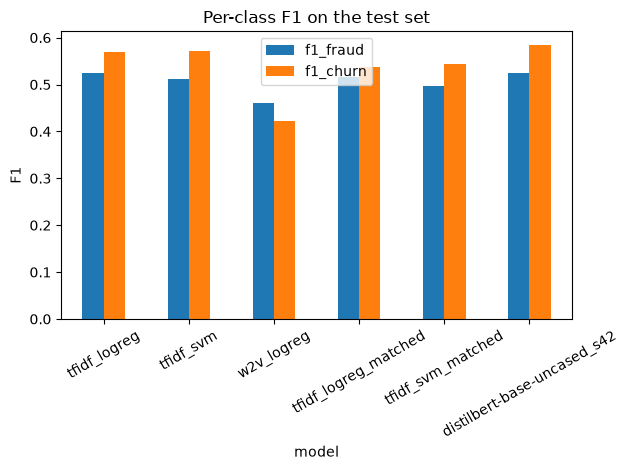

tfidf_logreg


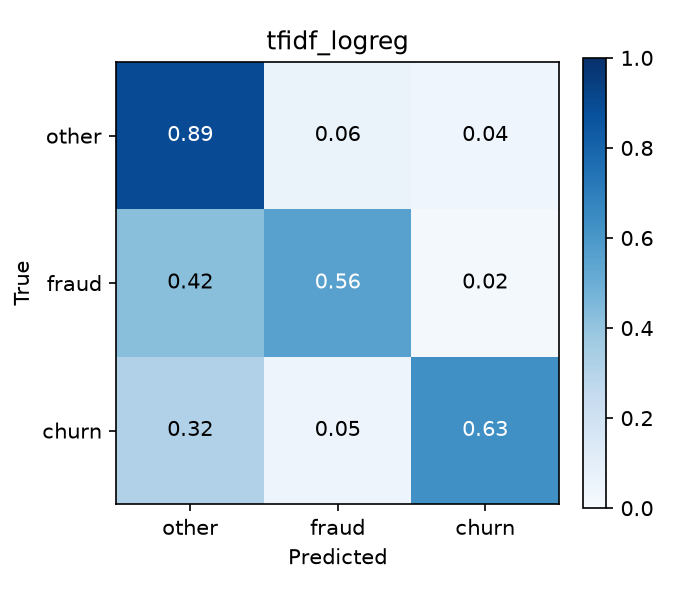

distilbert-base-uncased_s42


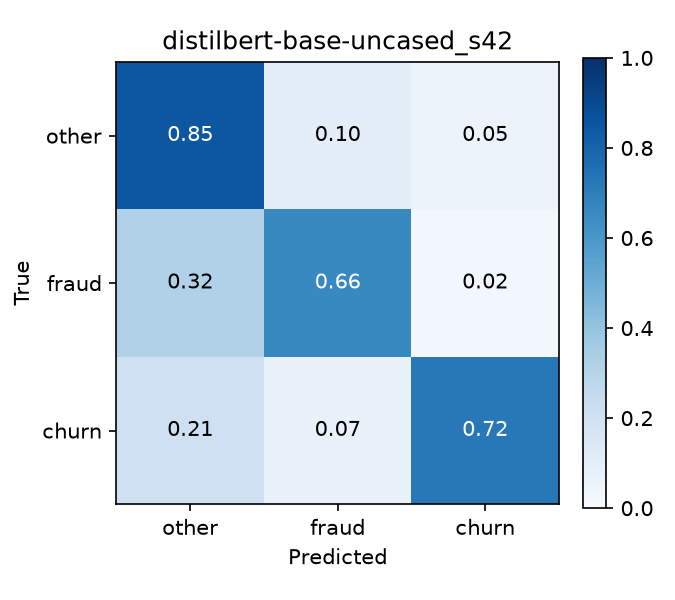

In [44]:
allres.set_index("model")[["f1_fraud", "f1_churn"]].plot.bar(rot=30, title="Per-class F1 on the test set")
plt.ylabel("F1"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/per_class_f1.png", dpi=150); plt.show()

for m in ["tfidf_logreg"] + ([best_tf] if HAVE_TF else []):
    print(m)
    display(Image(f"{FIG_DIR}/cm_{m}.png", width=380))

> **✍️ Your reasoning:** Did the transformer beat the baselines, by how much, and is the difference reliable (both tests)? In which classes does it
> help? Given the label noise found in Stage 7, what limits further gains? Is the extra cost (compute, time, interpretability) justified?

## 10. Explainability (planned)

Not implemented yet. The plan, to be completed once a trained transformer is available:

1. **SHAP on a sample** (about 200 test complaints, because SHAP on a transformer is slow) to show which words push a complaint toward fraud or churn.
2. **Compare explanations**: Logistic Regression's own top terms (Stage 6.4) against SHAP for the same model, and against SHAP for the transformer.
3. **Faithfulness test**: remove the words SHAP calls most important and measure how much the model's confidence drops. If the explanation is faithful,
   the drop should be large, and larger than when removing random words.

> **✍️ Your reasoning (later):** What does an explanation add for a risk manager, and how do we know it can be trusted?

In [46]:
import pickle, textwrap
import joblib
import shap
from collections import defaultdict

N_EXPLAIN = 60          # complaints to explain, equal per true class. Start small; raise it if time allows
MAX_EVALS = 300         # model calls per complaint: more = more accurate, slower
RERUN_SHAP = False      # True: recompute even if saved explanations exist
MAX_WORDS = 195         # about 256 tokens, the window the transformer reads

def clip_words(text, n=MAX_WORDS):
    return " ".join(text.split()[:n])

per_class = N_EXPLAIN // 3
sample = pd.concat([g.sample(per_class, random_state=SEED) for _, g in splits["test"].groupby("label_id")]
                   ).reset_index(drop=True)
texts = [clip_words(t) for t in sample["text"]]
y_true_s = sample["label_id"].to_numpy()
print(f"Explaining {len(texts)} test complaints ({per_class} per class: {', '.join(LABEL_NAMES)})")

Explaining 60 test complaints (20 per class: other, fraud, churn)


### 10.1 The models to explain

SHAP only needs a function that turns a list of texts into class probabilities. For Logistic Regression that is the TF-IDF vectoriser
plus the classifier from Stage 6 (loaded from disk if saved, otherwise refitted with the same settings, which takes seconds).

In [47]:
vec_path, lr_path = f"{RESULTS_DIR}/models/tfidf_vectorizer.joblib", f"{RESULTS_DIR}/models/tfidf_logreg.joblib"
if os.path.exists(vec_path) and os.path.exists(lr_path):
    vec_x, lr_x = joblib.load(vec_path), joblib.load(lr_path)
    print("Loaded the saved TF-IDF vectoriser and Logistic Regression")
else:
    best_C = float(base.loc[base["model"] == "tfidf_logreg", "best_C"].iloc[0])
    vec_x = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2),
                            min_df=5, max_df=0.9, max_features=200_000, sublinear_tf=True)
    lr_x = LogisticRegression(C=best_C, max_iter=1000, class_weight="balanced", random_state=SEED
                              ).fit(vec_x.fit_transform(splits["train"]["text"]), ytr)
    print(f"Refitted Logistic Regression (C = {best_C})")

def f_lr(texts):
    return lr_x.predict_proba(vec_x.transform([str(t) for t in texts]))

# Consistency check: this must reproduce the Logistic Regression test score from Stage 6
check = compute_metrics(yte, f_lr(splits["test"]["text"]).argmax(1))["macro_f1"]
print(f"Test macro-F1 of this model: {check:.4f}  (Stage 6 reported {base.loc[base['model'] == 'tfidf_logreg', 'macro_f1'].iloc[0]:.4f})")

Loaded the saved TF-IDF vectoriser and Logistic Regression
Test macro-F1 of this model: 0.6668  (Stage 6 reported 0.6668)


In [48]:
def make_transformer_proba(model, tokenizer, device, max_len, batch_size=32):
    import torch
    model.eval()
    def f(texts):
        texts, out = [str(t) for t in texts], []
        with torch.no_grad():
            for i in range(0, len(texts), batch_size):
                enc = tokenizer(texts[i:i + batch_size], truncation=True, max_length=max_len,
                                padding=True, return_tensors="pt").to(device)
                out.append(torch.softmax(model(**enc).logits.float(), dim=-1).cpu().numpy())
        return np.vstack(out)
    return f

models = {"tfidf_logreg": f_lr}
tf_dir = Path(RESULTS_DIR) / "models" / best_tf if HAVE_TF else None      # best_tf comes from Stage 9
if tf_dir is not None and tf_dir.exists():
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok_x = AutoTokenizer.from_pretrained(CFG.model)
    dev_x = pick_device(CFG.device)
    tmodel = AutoModelForSequenceClassification.from_pretrained(str(tf_dir)).to(dev_x)
    models[best_tf] = make_transformer_proba(tmodel, tok_x, dev_x, CFG.max_len)
    print(f"Loaded the fine-tuned transformer {best_tf} on {dev_x}")
else:
    print("No saved transformer found in results/models/: only Logistic Regression will be explained.")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 6378.52it/s]


Loaded the fine-tuned transformer distilbert-base-uncased_s42 on mps


### 10.2 Computing the explanations

`explain` runs SHAP on each complaint and keeps the words and their contributions to **all three classes**. It saves the result, because
SHAP is slow and should not be recomputed by accident. The timing line shows how long the full sample will take; interrupt the cell
and lower `N_EXPLAIN` if it is too long.

In [49]:
def explain(name, f):
    cache = f"{RESULTS_DIR}/shap_{name}_n{N_EXPLAIN}_e{MAX_EVALS}.pkl"
    if os.path.exists(cache) and not RERUN_SHAP:
        print(f"[{name}] loading saved explanations")
        with open(cache, "rb") as fh:
            return pickle.load(fh)
    explainer = shap.Explainer(f, shap.maskers.Text(r"\W+"), output_names=LABEL_NAMES)   # word-level masking
    exs, t0 = [], time.time()
    for i, t in enumerate(texts):
        e = explainer([t], max_evals=MAX_EVALS, batch_size=32, silent=True)[0]
        exs.append({"tokens": list(e.data), "values": np.asarray(e.values)})
        if i in (0, 4) or (i + 1) % 10 == 0:
            el = time.time() - t0
            print(f"  [{name}] {i + 1}/{len(texts)} | {el / 60:.1f} min elapsed, ~{el / (i + 1) * (len(texts) - i - 1) / 60:.1f} min left")
    out = {"examples": exs, "probs": f(texts)}
    with open(cache, "wb") as fh:
        pickle.dump(out, fh)
    return out

explained = {name: explain(name, f) for name, f in models.items()}
for name, out in explained.items():
    pred = out["probs"].argmax(1)
    print(f"{name}: predicts {[int((pred == k).sum()) for k in range(3)]} complaints as {LABEL_NAMES} (true: {[per_class] * 3})")

  [tfidf_logreg] 1/60 | 0.0 min elapsed, ~0.1 min left
  [tfidf_logreg] 5/60 | 0.0 min elapsed, ~0.1 min left
  [tfidf_logreg] 10/60 | 0.0 min elapsed, ~0.0 min left
  [tfidf_logreg] 20/60 | 0.0 min elapsed, ~0.0 min left
  [tfidf_logreg] 30/60 | 0.0 min elapsed, ~0.0 min left
  [tfidf_logreg] 40/60 | 0.0 min elapsed, ~0.0 min left
  [tfidf_logreg] 50/60 | 0.0 min elapsed, ~0.0 min left
  [tfidf_logreg] 60/60 | 0.0 min elapsed, ~0.0 min left
  [distilbert-base-uncased_s42] 1/60 | 0.2 min elapsed, ~11.8 min left
  [distilbert-base-uncased_s42] 5/60 | 0.5 min elapsed, ~5.0 min left
  [distilbert-base-uncased_s42] 10/60 | 0.8 min elapsed, ~4.1 min left
  [distilbert-base-uncased_s42] 20/60 | 1.4 min elapsed, ~2.7 min left
  [distilbert-base-uncased_s42] 30/60 | 1.9 min elapsed, ~1.9 min left
  [distilbert-base-uncased_s42] 40/60 | 2.6 min elapsed, ~1.3 min left
  [distilbert-base-uncased_s42] 50/60 | 3.2 min elapsed, ~0.6 min left
  [distilbert-base-uncased_s42] 60/60 | 4.0 min elapsed, ~

### 10.3 One complaint, in detail

For a single complaint: what each model predicted, and the words that pushed it toward that class (positive) or away from it (negative).

In [50]:
def clean_word(tok):
    return re.sub(r"\W+", "", tok.lower())

def top_words(ex, k, n=8):
    toks, vals = [clean_word(t) for t in ex["tokens"]], ex["values"][:, k]
    order = np.argsort(-vals)
    pos = [(toks[j], round(float(vals[j]), 3)) for j in order[:n] if vals[j] > 0]
    neg = [(toks[j], round(float(vals[j]), 3)) for j in order[::-1][:5] if vals[j] < 0]
    return pos, neg

def show_example(i):
    print(f"TRUE CLASS: {LABEL_NAMES[y_true_s[i]]} | Issue: {sample.loc[i, 'Issue']}")
    print(textwrap.fill(texts[i][:600], 100) + " ...\n")
    for name, out in explained.items():
        p = out["probs"][i]; k = int(p.argmax())
        pos, neg = top_words(out["examples"][i], k)
        print(f"[{name}] predicts '{LABEL_NAMES[k]}' (probabilities {np.round(p, 2)})")
        print("   pushes toward it:", pos)
        print("   pushes away:     ", neg, "\n")

for cls in (1, 2):                                   # one fraud and one churn complaint
    show_example(int(np.where(y_true_s == cls)[0][0]))
    print("-" * 100)

TRUE CLASS: fraud | Issue: Unauthorized transactions or other transaction problem
I have filed reports saying there was an transaction and cash app won't do anything about it this is
a lot of money to go missing.i don't know what to do cash app is not telling me why they can't
refund it it just says denied. ...

[tfidf_logreg] predicts 'other' (probabilities [0.7 0.3 0. ])
   pushes toward it: [('says', 0.101), ('denied', 0.089), ('telling', 0.058), ('missing', 0.055), ('money', 0.041), ('just', 0.03), ('it', 0.03), ('i', 0.024)]
   pushes away:      [('app', -0.182), ('app', -0.169), ('cash', -0.141), ('cash', -0.089), ('transaction', -0.043)] 

[distilbert-base-uncased_s42] predicts 'fraud' (probabilities [0.03 0.96 0.01])
   pushes toward it: [('app', 0.187), ('app', 0.123), ('cash', 0.076), ('was', 0.06), ('transaction', 0.051), ('cash', 0.048), ('money', 0.047), ('an', 0.046)]
   pushes away:      [('refund', -0.042), ('denied', -0.026), ('won', -0.024), ('i', -0.018), ('t', -0.01

### 10.4 Do the models rely on the same words?

Across the complaints a model flagged as fraud (or churn), which words have the highest *average* contribution? `min_count` drops words
seen too rarely to trust. Then compare with Logistic Regression's own top terms from Stage 6.4, and with the transformer.

With a sample this small the rankings are **indicative, not definitive**.

--- fraud | tfidf_logreg: top words by average SHAP (flagged complaints: 15) ---


,word,mean_shap,n
0,opened,0.197,7
1,identity,0.079,4
2,application,0.075,3
3,scam,0.066,6
4,email,0.065,3
5,theft,0.062,6
6,coinbase,0.046,4
7,fraudulent,0.045,9
8,cashapp,0.040,7
9,police,0.039,5


--- fraud | distilbert-base-uncased_s42: top words by average SHAP (flagged complaints: 18) ---


,word,mean_shap,n
0,scammed,0.150,3
1,opened,0.106,6
2,scam,0.077,6
3,identity,0.063,4
4,fraudulent,0.056,8
5,email,0.047,3
6,app,0.044,20
7,cash,0.042,12
8,theft,0.041,6
9,victim,0.033,4


fraud: 8 of tfidf_logreg's top-15 SHAP words are among Logistic Regression's own top-25 terms
fraud: 7 of distilbert-base-uncased_s42's top-15 SHAP words are among Logistic Regression's own top-25 terms
fraud: the two models share 10 of their top-15 SHAP words

--- churn | tfidf_logreg: top words by average SHAP (flagged complaints: 12) ---


,word,mean_shap,n
0,close,0.185,6
1,closure,0.163,9
2,closing,0.090,3
3,closed,0.075,16
4,remaining,0.050,3
5,account,0.044,36
6,check,0.029,8
7,chase,0.022,6
8,once,0.021,3
9,just,0.021,5


--- churn | distilbert-base-uncased_s42: top words by average SHAP (flagged complaints: 15) ---


,word,mean_shap,n
0,closing,0.265,5
1,closure,0.192,10
2,closed,0.125,18
3,close,0.091,8
4,closures,0.065,3
5,were,0.036,9
6,card,0.020,9
7,required,0.018,3
8,account,0.017,45
9,once,0.016,3


churn: 7 of tfidf_logreg's top-15 SHAP words are among Logistic Regression's own top-25 terms
churn: 7 of distilbert-base-uncased_s42's top-15 SHAP words are among Logistic Regression's own top-25 terms
churn: the two models share 9 of their top-15 SHAP words



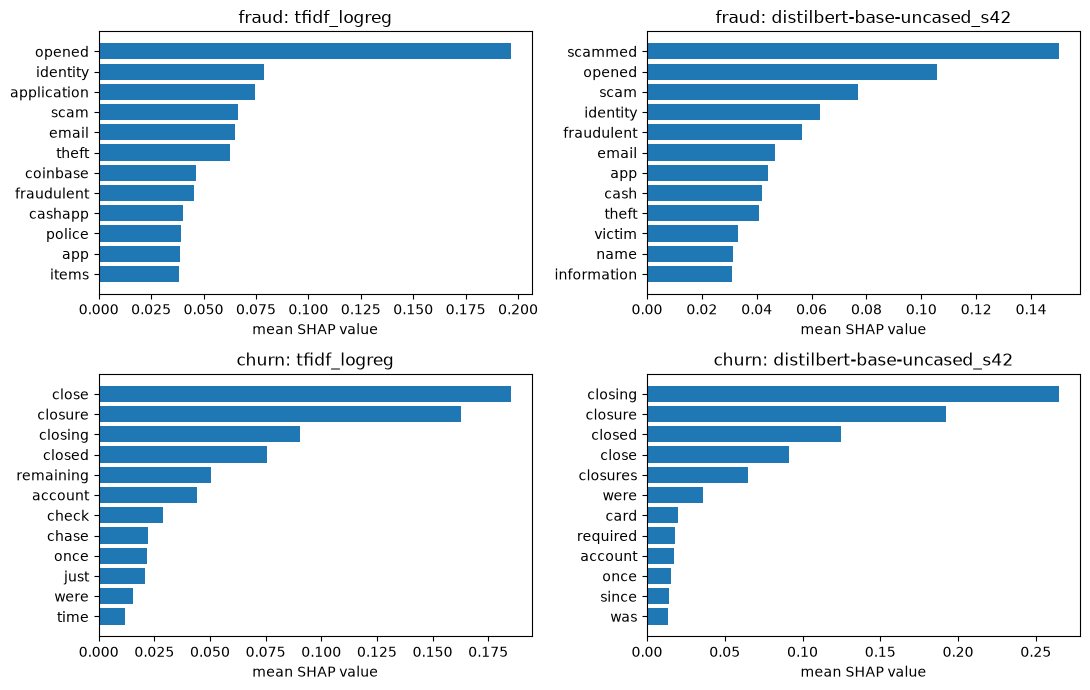

In [51]:
def aggregate(name, class_id, min_count=3):
    out = explained[name]
    tot, cnt = defaultdict(float), defaultdict(int)
    for ex, p in zip(out["examples"], out["probs"].argmax(1)):
        if p != class_id:
            continue
        for tok, v in zip(ex["tokens"], ex["values"][:, class_id]):
            w = clean_word(tok)
            if len(w) >= 3:
                tot[w] += v; cnt[w] += 1
    d = pd.DataFrame({"word": list(tot), "mean_shap": [tot[w] / cnt[w] for w in tot], "n": [cnt[w] for w in tot]})
    return d[d["n"] >= min_count].sort_values("mean_shap", ascending=False).reset_index(drop=True)

terms = pd.read_csv(f"{RESULTS_DIR}/lr_top_terms.csv")
def coef_words(cls):                                  # unigrams from Logistic Regression's top terms
    return {w for t in terms[terms["class"] == cls]["term"] for w in t.split() if len(w) >= 3}

fig, axes = plt.subplots(2, len(explained), figsize=(5.5 * len(explained), 7), squeeze=False)
for r, (cls, k) in enumerate([("fraud", 1), ("churn", 2)]):
    ref, tops = coef_words(cls), {}
    for c, name in enumerate(explained):
        agg = aggregate(name, k)
        tops[name] = set(agg.head(15)["word"])
        print(f"--- {cls} | {name}: top words by average SHAP (flagged complaints: {int((explained[name]['probs'].argmax(1) == k).sum())}) ---")
        display(agg.head(12).round(3))
        if len(agg):
            axes[r][c].barh(agg.head(12)["word"][::-1], agg.head(12)["mean_shap"][::-1])
        axes[r][c].set_title(f"{cls}: {name}")
        axes[r][c].set_xlabel("mean SHAP value")
    for name, t in tops.items():
        print(f"{cls}: {len(t & ref)} of {name}'s top-15 SHAP words are among Logistic Regression's own top-25 terms")
    if len(tops) == 2:
        a, b = list(tops.values())
        print(f"{cls}: the two models share {len(a & b)} of their top-15 SHAP words\n")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/shap_top_words.png", dpi=150); plt.show()

> **✍️ Your reasoning:** Are the top words sensible for fraud and for churn? Do Logistic Regression and the transformer rely on the
> same words, or does the transformer use different evidence? Do the words match Logistic Regression's own coefficients (a sanity check that
> SHAP is behaving)? Is anything surprising or spurious? Remember the sample is small.

### 10.5 Can the explanations be trusted? A faithfulness (deletion) test

An explanation is only useful if it points at words the model really depends on. Test: for complaints the model flagged as a risk class,
**delete the k words SHAP rated most important** for that class and see how much the model's probability for that class falls. Compare
with deleting **k random words**. If SHAP is faithful, deleting its top words should hurt much more than deleting random ones.

--- tfidf_logreg: drop in the predicted class's probability after removing words ---


,k_words_removed,n_complaints,mean_drop_SHAP_top,mean_drop_random,share_SHAP_hurts_more,pred_flips_SHAP_top
0,1,27,0.120,0.004,0.926,0.296
1,3,27,0.283,0.015,1.000,0.481
2,5,27,0.378,0.024,1.000,0.593
3,10,27,0.504,0.043,1.000,0.704


--- distilbert-base-uncased_s42: drop in the predicted class's probability after removing words ---


,k_words_removed,n_complaints,mean_drop_SHAP_top,mean_drop_random,share_SHAP_hurts_more,pred_flips_SHAP_top
0,1,33,0.127,0.001,0.879,0.182
1,3,33,0.329,0.016,0.970,0.424
2,5,33,0.434,0.018,1.000,0.545
3,10,33,0.567,0.044,1.000,0.758


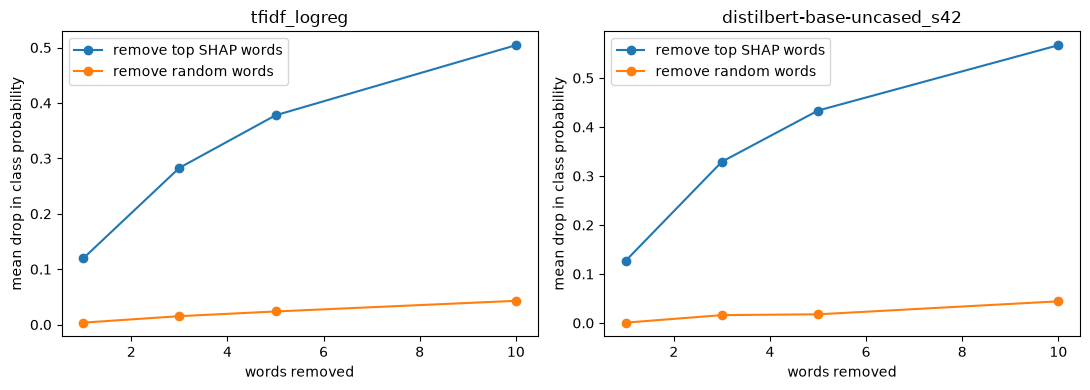

In [52]:
def deletion_test(f, out, ks=(1, 3, 5, 10), n_random=5, seed=SEED):
    rng = np.random.default_rng(seed)
    probs, exs = out["probs"], out["examples"]
    pred = probs.argmax(1)
    idx = [i for i in range(len(exs)) if pred[i] != 0]                 # only complaints flagged as fraud or churn
    if not idx:
        return pd.DataFrame()
    cls, p0 = pred[idx], probs[idx, pred[idx]]
    rows = []
    for k in ks:
        top_texts, rand_texts = [], []
        for i in idx:
            toks, vals = exs[i]["tokens"], exs[i]["values"][:, pred[i]]
            kk = min(k, len(toks))
            drop_top = set(np.argsort(-vals)[:kk])
            top_texts.append("".join(t for j, t in enumerate(toks) if j not in drop_top))
            for _ in range(n_random):
                drop_rand = set(rng.choice(len(toks), kk, replace=False))
                rand_texts.append("".join(t for j, t in enumerate(toks) if j not in drop_rand))
        p_top_all, p_rand_all = f(top_texts), f(rand_texts)
        p_top = p_top_all[np.arange(len(idx)), cls]
        p_rand = p_rand_all[np.arange(len(p_rand_all)), np.repeat(cls, n_random)].reshape(len(idx), n_random).mean(1)
        rows.append({"k_words_removed": k, "n_complaints": len(idx),
                     "mean_drop_SHAP_top": float((p0 - p_top).mean()),
                     "mean_drop_random": float((p0 - p_rand).mean()),
                     "share_SHAP_hurts_more": float(((p0 - p_top) > (p0 - p_rand)).mean()),
                     "pred_flips_SHAP_top": float((p_top_all.argmax(1) != cls).mean())})
    return pd.DataFrame(rows)

faith = {name: deletion_test(models[name], explained[name]) for name in explained}
for name, d in faith.items():
    print(f"--- {name}: drop in the predicted class's probability after removing words ---")
    display(d.round(3))

fig, axes = plt.subplots(1, len(faith), figsize=(5.5 * len(faith), 4), squeeze=False)
for ax, (name, d) in zip(axes[0], faith.items()):
    if len(d):
        ax.plot(d["k_words_removed"], d["mean_drop_SHAP_top"], marker="o", label="remove top SHAP words")
        ax.plot(d["k_words_removed"], d["mean_drop_random"], marker="o", label="remove random words")
    ax.set_title(name); ax.set_xlabel("words removed"); ax.set_ylabel("mean drop in class probability"); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/shap_faithfulness.png", dpi=150); plt.show()

> **✍️ Your reasoning:** Is the drop after removing SHAP's top words larger than after removing random words, for each model? What does that
> say about whether the explanations can be trusted? Does one model's explanations look more faithful than the other's, and what could cause that?
>
> **Limits to state honestly:** a small, class-balanced sample; SHAP approximated with limited evaluations; words are hidden with a
> placeholder in SHAP but deleted in this test; only one faithfulness check; one trained transformer (one seed).

## 11. Limitations and conclusions

> **✍️ Your reasoning:** Write these yourself once the results are in. Points to consider:
>
> - **Labels:** built from the Issue category the customer chose, so partly category prediction; some label noise (Stage 7).
> - **Triage, not early warning:** complaints arrive after the event.
> - **Data:** an archived snapshot (the live CFPB database no longer has narratives); only opt-in complaints; banking products only.
> - **Drift:** the class mix changes over time, so the test set is harder than validation.
> - **Compute:** a subsample for fine-tuning, few seeds; DistilBERT instead of a larger model.
> - **Scope change:** the proposal's Twitter data was not used (paid, limited API); a free bank-tweet dataset could serve as a cross-domain test.
>
> **Conclusion:** answer the research question directly, in a few sentences, using your numbers.

### 11.1 One table for the report

Every model on the same test set, with how much training data it saw. It is saved to `results/final_results_table.csv`.

In [53]:
rows_seen = {m: (len(subset) if ("matched" in m or m.startswith("distilbert")) else len(ytr)) for m in allres["model"]}
final = allres.copy()
final.insert(1, "train_rows", final["model"].map(rows_seen))
final["macro_f1 (95% CI)"] = [f"{m:.3f} ({lo:.3f} to {hi:.3f})" for m, lo, hi in
                              zip(final["macro_f1"], final["macro_f1_ci_low"], final["macro_f1_ci_high"])]
final = final[["model", "train_rows", "macro_f1 (95% CI)", "accuracy", "pr_auc_macro", "f1_fraud", "f1_churn", "val_macro_f1"]]
final.to_csv(f"{RESULTS_DIR}/final_results_table.csv", index=False)
display(final.round(3))
print("Saved to", f"{RESULTS_DIR}/final_results_table.csv", "| transformer rows come from one seed unless several were trained")

,model,train_rows,macro_f1 (95% CI),accuracy,pr_auc_macro,f1_fraud,f1_churn,val_macro_f1
0,tfidf_logreg,42000,0.667 (0.651 to 0.683),0.843,0.682,0.525,0.568,0.657
1,tfidf_svm,42000,0.666 (0.650 to 0.682),0.852,0.689,0.511,0.572,0.658
2,w2v_logreg,42000,0.560 (0.547 to 0.573),0.698,0.613,0.461,0.421,0.550
3,tfidf_logreg_matched,14999,0.653 (0.636 to 0.668),0.840,0.672,0.515,0.537,0.644
4,tfidf_svm_matched,14999,0.652 (0.635 to 0.668),0.852,0.678,0.496,0.545,0.644
5,distilbert-base-uncased_s42,14999,0.667 (0.652 to 0.682),0.822,0.692,0.524,0.584,0.662


Saved to results/final_results_table.csv | transformer rows come from one seed unless several were trained


## Appendix: reproducibility record

Library versions and settings that produced these results.

In [54]:
import sklearn
info = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__}
for pkg in ("torch", "transformers", "gensim"):
    try:
        info[pkg] = __import__(pkg).__version__
    except Exception:
        info[pkg] = "not installed"
print(info)
print(f"seed={SEED} | subsample={SUBSAMPLE_N:,} | min_year={MIN_YEAR} | min_words={MIN_WORDS} | transformer config: {vars(CFG)}")

{'python': '3.12.16', 'pandas': '3.1.0', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'torch': '2.11.0', 'transformers': '5.22.2', 'gensim': '4.4.0'}
seed=42 | subsample=60,000 | min_year=2020 | min_words=10 | transformer config: {'model': 'distilbert-base-uncased', 'max_len': 256, 'epochs': 2, 'batch_size': 16, 'lr': 2e-05, 'seeds': [42], 'max_train': 15000, 'max_val': 0, 'max_test': 0, 'subsample_seed': 42, 'device': 'auto', 'no_save_model': False}
